# Strip waveguide directional coupler

In [1]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install -r pyproject.toml

%matplotlib widget

# Standard library imports
from datetime import datetime
import math

# Import modules
from IPython.display import display
import lumapi as lma
import matplotlib.pyplot as plt
import numpy as np
import photonix as px

In [2]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [3]:
# Constants

um = 1e-6
nm = 1e-9
C = 299792458

# Simulation input

| Parameter                   | Description                                                                   | Example                           |
| :---------------------------| :-----------------------------------------------------------------------------| :---------------------------------|
| **wavelength_center**       | Wavelength for which simulation will be done.                                 | `1.55*um`                         |
| **wavelength_span**         | Span of the wavelength for which simulation will be done.                     | `0.15*um`                         |
| **gap_sweep**               | Array with gap widths that will be used during sweep.                         | `np.arange(10*nm, 900*nm, 25*nm)` |
| **core_thickness**          | Thickness of the strip waveguide core.                                        | `220*nm`                          |
| **core_width**              | Width of the strip waveguide core.                                            | `500*nm`                          |
| **bottom_clad_thickness**   | Thickness of the bottom cladding layer.                                       | `3*um`                            |
| **top_clad_thickness**      | Thickness of the top cladding layer.                                          | `2*um`                            |
| **base_core_material**      | Material of strip waveguide core as defined in Lumerical's materials library. | `Si (Silicon) - Palik`            |
| **base_clad_material**      | Material of strip waveguide clad as defined in Lumerical's materials library. | `SiO2 (Glass) - Palik`            |
| **base_substrate_material** | Material of substrate as defined in Lumerical's materials library.            | `Si (Silicon) - Palik`            |

In [4]:
# Si/SiO2/Si 500x220nm 1550nm
wavelength_center = 1.55*um
wavelength_span = 0.15*um

gap_sweep = np.arange(10*nm, 900*nm, 25*nm)
coupler_gap = 400*nm

core_thickness = 220*nm
core_width = 500*nm

bottom_clad_thickness = 3*um
top_clad_thickness = 2*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
base_core_material = "Si (Silicon) - Palik"
base_clad_material = "SiO2 (Glass) - Palik"
base_substrate_material = "Si (Silicon) - Palik"

In [5]:
# Si3n4/SiO2/Si 1000x220nm 1550nm
wavelength_center = 1.55*um
wavelength_span = 0.15*um

gap_sweep = np.arange(375*nm, 425*nm, 5*nm)
coupler_gap = 400*nm

core_thickness = 360*nm
core_width = 1000*nm

bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
base_core_material = "Si3N4 (Silicon Nitride) - Luke"
base_clad_material = "SiO2 (Glass) - Palik"
base_substrate_material = "Si (Silicon) - Palik"

In [6]:
# Pre-calculate parameters for experiment

experiment_name = (
    f"{base_core_material.split()[0].lower()}_"
    f"w{int(core_width / nm)}nm_"
    f"h{int(core_thickness / nm)}nm_"
    f"dc_gsweep"
)

field_intensity_log_decay = -6

ports_offset = 0
initial_ports_width = 1*core_width
initial_ports_height = 6*core_thickness

fde_buffer = 1*wavelength_center


In [7]:
# Get solver
solver = lma.MODE(hide=False)

In [8]:
# Helpers

def remove(object_name):
    try:
        solver.select(object_name)
        solver.delete()
    except:
        pass

# Materials

Material fitting is done using Lumerical's built-in utility of multi-coefficient model.

| Parameter            | Expression                            |
| :------------------- | :------------------------------------ |
| **tolerance**        | 0.001 (hardcoded)                     |
| **max coefficients** | 6 (hardcoded)                         |
| **wavelength min**   | wavelength_center - wavelength_span/2 |
| **wavelength max**   | wavelength_center + wavelength_span/2 |

In [9]:
# Materials fitting

def fit_material(material_name):
    wvl_min = wavelength_center - wavelength_span/2
    wvl_max = wavelength_center + wavelength_span/2

    try:
        solver.deletematerial(f"{material_name} Fitted")
    except:
        pass

    material_fitted = solver.copymaterial(material_name)
    
    material_params = {
        "tolerance": 0.001,
        "max coefficients": 6,
        "specify fit range": True,
        "wavelength min": wvl_min,
        "wavelength max": wvl_max,
        "name": f"{material_name} Fitted"
    }
    
    solver.setmaterial(material_fitted, material_params)
    
    return f"{material_name} Fitted"

core_material = fit_material(base_core_material)
clad_material = fit_material(base_clad_material)
substrate_material = fit_material(base_substrate_material)

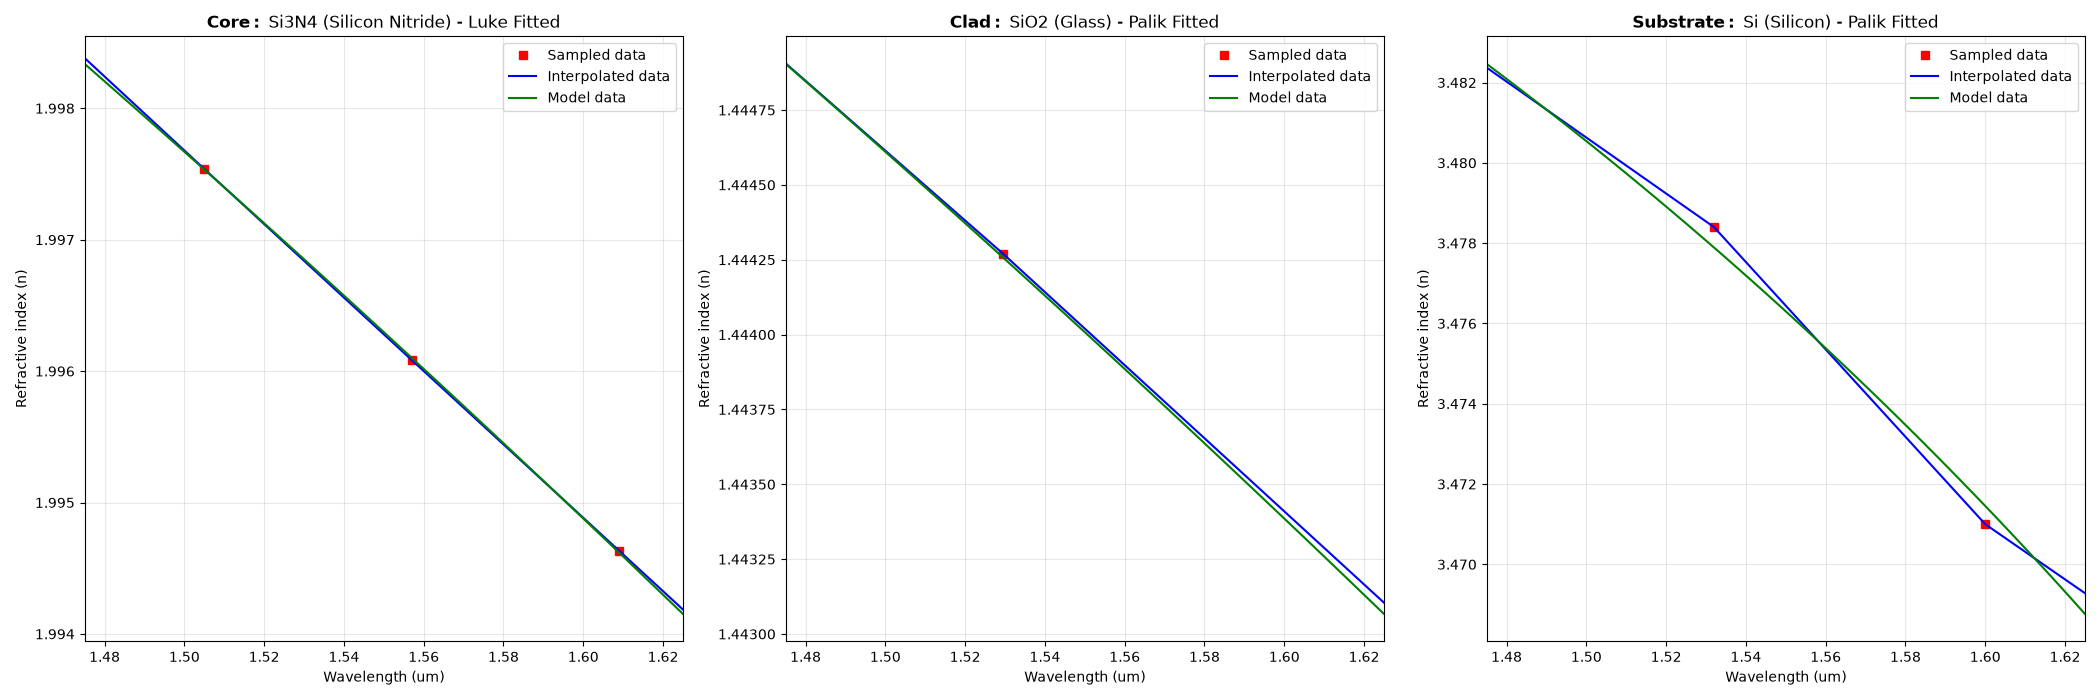

In [10]:
# Materials fit preview

def plot_material(material, ax):
    ax.set_title(material)

    wvl_min = solver.getmaterial(material, "wavelength min")
    wvl_max = solver.getmaterial(material, "wavelength max")

    mat_permitivity_samples = solver.getmaterial(material, "sampled data")

    f1 = mat_permitivity_samples[:, 0]
    mat_n_interpolated = solver.getindex(material, f1).squeeze()
    mat_n_interpolated = np.column_stack((f1, mat_n_interpolated))

    f2 = C / np.linspace(wvl_min, wvl_max, 100)
    fmin = np.min(f2)
    fmax = np.max(f2)
    mat_n_model = solver.getmodeindex(material, f2, 1, 1, 0, fmin, fmax);
    mat_n_model = np.column_stack((f2, mat_n_model))

    px.plot_material_n(
        mat_permitivity_samples,
        mat_n_interpolated,
        mat_n_model=mat_n_model,
        wavelength_min=wvl_min, wavelength_max=wvl_max,
        ax=ax
    )

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7))

# Core
plot_material(core_material, ax1)
ax1.set_title(f"$\\bf{{Core:}}$ {core_material}")

# Clad
plot_material(clad_material, ax2)
ax2.set_title(f"$\\bf{{Clad:}}$ {clad_material}")

# Substrate
plot_material(substrate_material, ax3)
ax3.set_title(f"$\\bf{{Substrate:}}$ {substrate_material}")

fig.tight_layout()
plt.show()

# Structures

Once the material properties have been defined, the geometry of the structures under investigation must be specified. \
The following section describes the creation of the substrate slab, cladding layers, and the complete directional coupler structure. \
Classic directional coupler consist:
- Two paraller waveguides responsible for main coupling region.
- Four S-bends acting as connectors to main coupling region.

| Parameter               | Expression         |
| :---------------------- | :------------------|
| **substrate_thickness** | 100 µm (hardcoded) |
| **substrate:x_span**    | 100 µm (hardcoded) |
| **substrate:y_span**    | 100 µm (hardcoded) |
| **clad:x_span**         | 100 µm (hardcoded) |
| **clad:y_span**         | 100 µm (hardcoded) |

In [11]:
# Structure geometry

# Clad
clad_thickness = bottom_clad_thickness + core_thickness + top_clad_thickness
clad_center_z = (top_clad_thickness - bottom_clad_thickness) / 2
clad_rect = {
    "name":"clad",
    "x":0, "y":0, "z":clad_center_z,
    "x span":100*um, "y span":100*um, "z span":clad_thickness,
    "material":clad_material,
    "alpha":0.3,
}

remove(clad_rect["name"])
solver.addrect(clad_rect)

# Substrate
substrate_thickness = 100*um
substrate_z_max = clad_center_z - clad_thickness/2
substrate_z_min = substrate_z_max - substrate_thickness
substrate_rect = {
    "name": "substrate",
    "x": 0, "y": 0, "z max": substrate_z_max, "z min": substrate_z_min,
    "x span": 100*um, "y span": 100*um,
    "material": substrate_material,
    "alpha": 0.8,
}

remove(substrate_rect["name"])
solver.addrect(substrate_rect)

# Coupler group
remove("coupler")
solver.addstructuregroup(name="coupler")

# Core 1
core1_y = -(core_width + coupler_gap)/2
core1_rect = {
    "name": "core1",
    "x": 0, "y": core1_y, "z": 0,
    "x span": 1*um, "y span": core_width, "z span": core_thickness,
    "material": core_material,
}

remove(core1_rect["name"])
solver.addrect(core1_rect)
solver.addtogroup("coupler")

# Core 2
core2_y = +(core_width + coupler_gap)/2
core2_rect = {
    "name": "core2",
    "y": core2_y, "x": 0, "z": 0,
    "y span": core_width, "x span": 1*um, "z span": core_thickness,
    "material": core_material,
}

remove(core2_rect["name"])
solver.addrect(core2_rect)
solver.addtogroup("coupler")


# Simulation setup

<img src="assets/stripWaveguide_directionalCoupler_gapSweep_modeSimulation.png" width="800">

In [33]:
# Simulation setup

solver.switchtolayout()

initial_fde_width = 4*(2*core_width + coupler_gap)
initial_fde_height = 20*core_thickness

remove("FDE")
solver.addfde(
    solver_type="2D X Normal",
    x=0,
    y=0, y_span = initial_fde_width,
    z=0, z_span = initial_fde_height,
    number_of_trial_modes=10,
    wavelength=wavelength_center,
)

# Mesh override
remove("mesh")
solver.addmesh(
    set_mesh_multiplier=True,
    x_mesh_multiplier=10,
    y_mesh_multiplier=10,
    z_mesh_multiplier=10,
    based_on_a_structure=True,
    structure="coupler",
    buffer=core_thickness/5, 
)

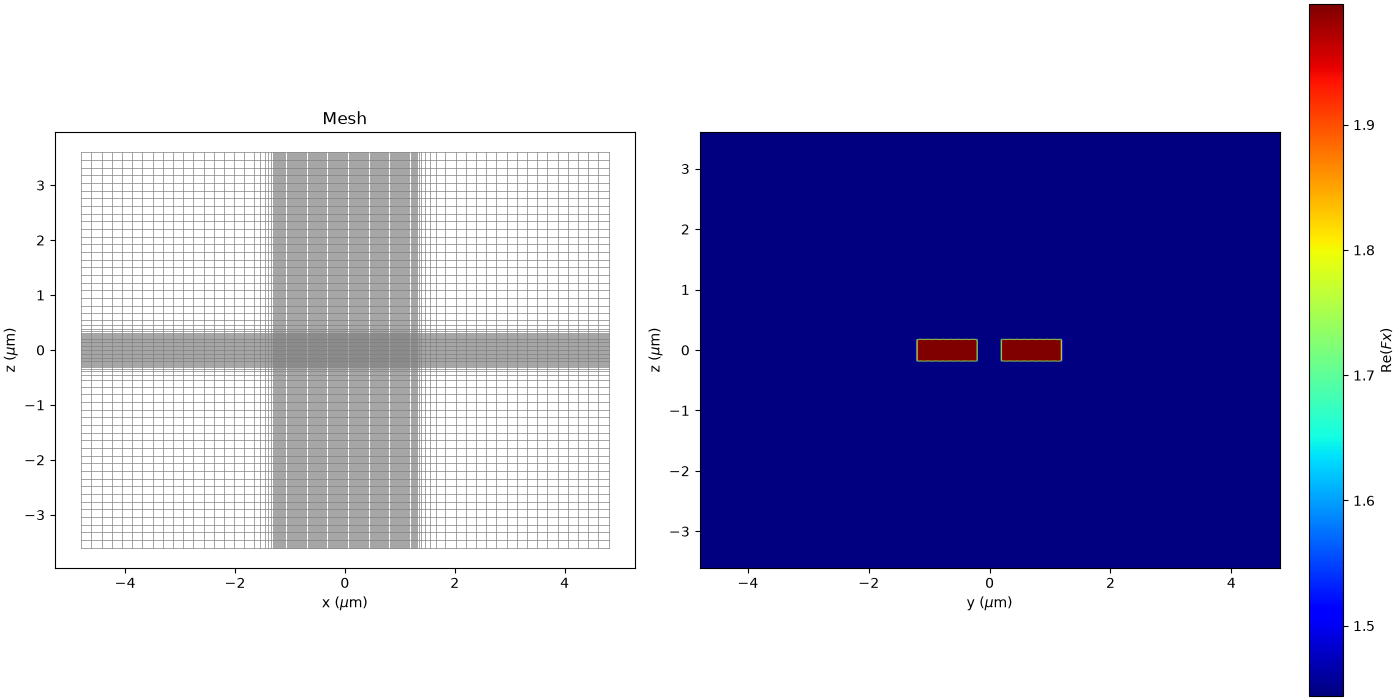

Current core width: 1000.0 nm
Current core height: 360.0 nm
Current coupler gap: 400.0 nm
Current fde width: 9.60 um
Current fde height: 7.20 um


In [34]:
# Simulation preview

solver.switchtolayout()

solver.mesh()
index = solver.getresult("FDE::data::material", "index")
index_x, index_y, index_z = [np.squeeze(index[f"index_{a}"]) for a in ["x", "y", "z"]]
y, z = np.squeeze(index["y"]), np.squeeze(index["z"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Grid
Y, Z = np.meshgrid(y, z, indexing='ij')
ax1.plot(Y* 1e6, Z * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.plot(Y.T * 1e6, Z.T * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.set_title('Mesh')
ax1.set_xlabel(r'x ($\mu$m)')
ax1.set_ylabel(r'z ($\mu$m)')
ax1.set_aspect('equal')

px.plot_field(
    Fx=index_y,
    y=y*1e6, z=z*1e6,
    ax=ax2,
    scale="lin",
    # vmin=0,
    # vmax=5,
)
plt.show()

current_core_width = solver.getnamed("coupler::core1", "x span")
current_core_height = solver.getnamed("coupler::core1", "z span")
current_fde_width = solver.getnamed("FDE", "y span")
current_fde_height = solver.getnamed("FDE", "z span")

print(f"Current core width: {current_core_width*1e9:.1f} nm")
print(f"Current core height: {current_core_height*1e9:.1f} nm")
print(f"Current coupler gap: {coupler_gap*1e9:.1f} nm")
print(f"Current fde width: {current_fde_width*1e6:.2f} um")
print(f"Current fde height: {current_fde_height*1e6:.2f} um")

# MODE simulation

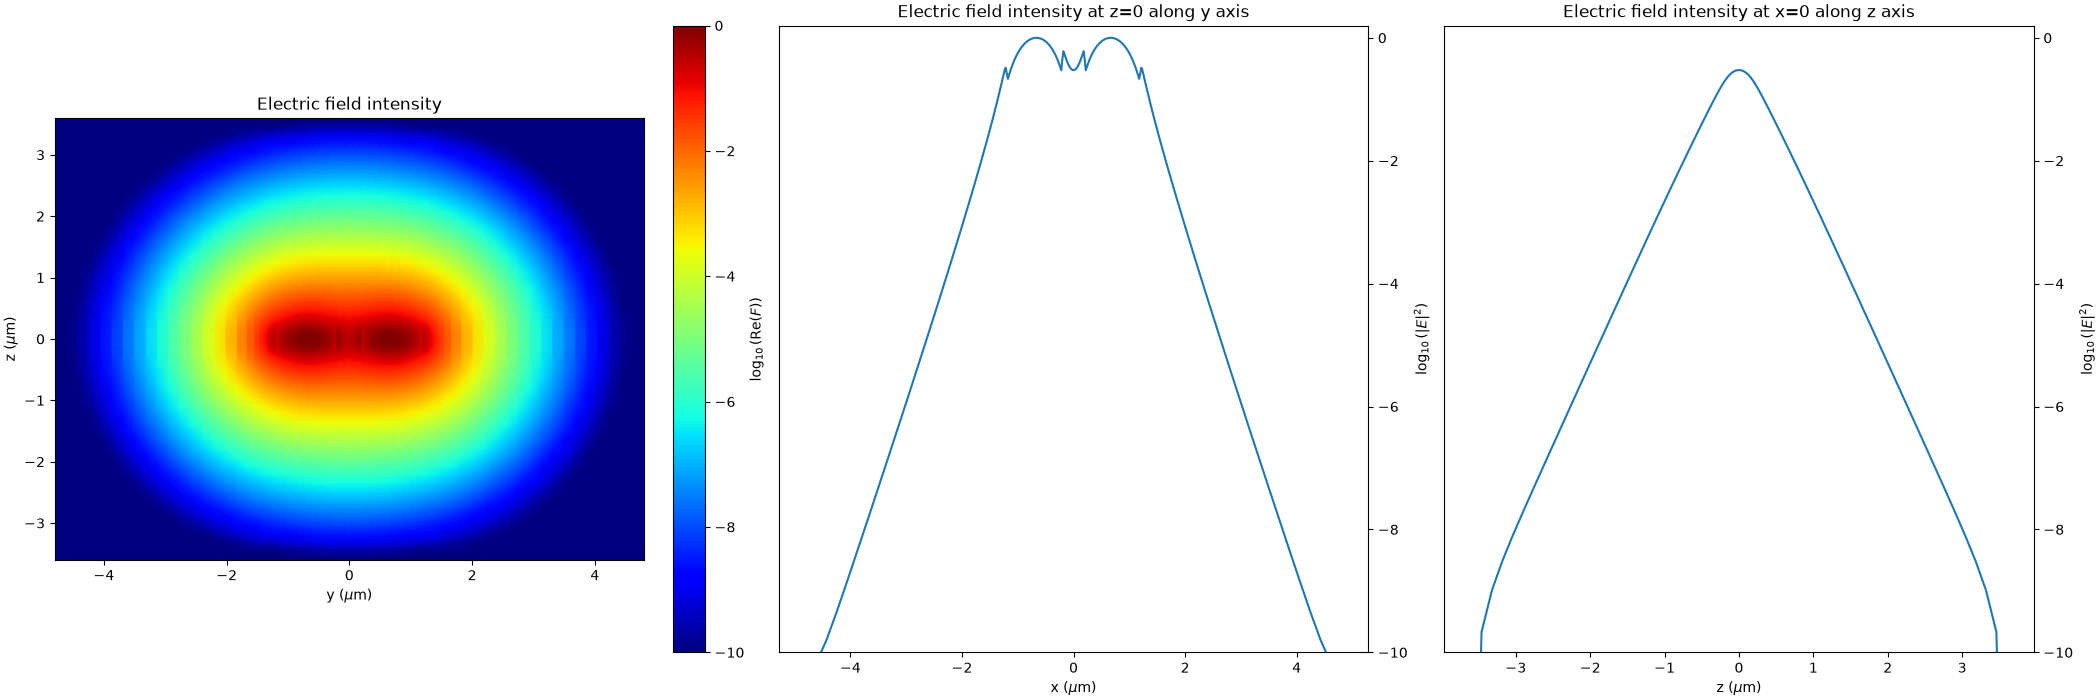

In [35]:
# Initial simulation

solver.findmodes()

E = solver.getresult("FDE::data::mode1", "E")
Ex, Ey, Ez = [np.squeeze(E["E"][..., i]) for i in range(3)]
y, z = np.squeeze(E["y"]), np.squeeze(E["z"])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7), constrained_layout=True)

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    y=y*1e6, z=z*1e6,
    vmin=-10, vmax=0,
    ax=ax1
)
ax1.set_title('Electric field intensity')

# Y decay
Eslice_y = px.get_field_intensisty_slice(
    Ex, Ey, Ez,
    y=y,
    scale="log"
)
ax2.plot(y*1e6, Eslice_y)
ax2.set_title('Electric field intensity at z=0 along y axis')
ax2.set_xlabel(r'x ($\mu$m)')
ax2.set_ylabel(r'$\log_{10}(|E|^2)$')
ax2.yaxis.tick_right()
ax2.yaxis.set_label_position("right")
ax2.set_ylim(-10, 0.2)

# Z decay
Eslice_z = px.get_field_intensisty_slice(
    Ex, Ey, Ez,
    z=z,
    scale="log"
)
ax3.plot(z*1e6, Eslice_z)
ax3.set_title('Electric field intensity at x=0 along z axis')
ax3.set_xlabel(r'z ($\mu$m)')
ax3.set_ylabel(r'$\log_{10}(|E|^2)$')
ax3.yaxis.tick_right()
ax3.yaxis.set_label_position("right")
ax3.set_ylim(-10, 0.2)

plt.show()

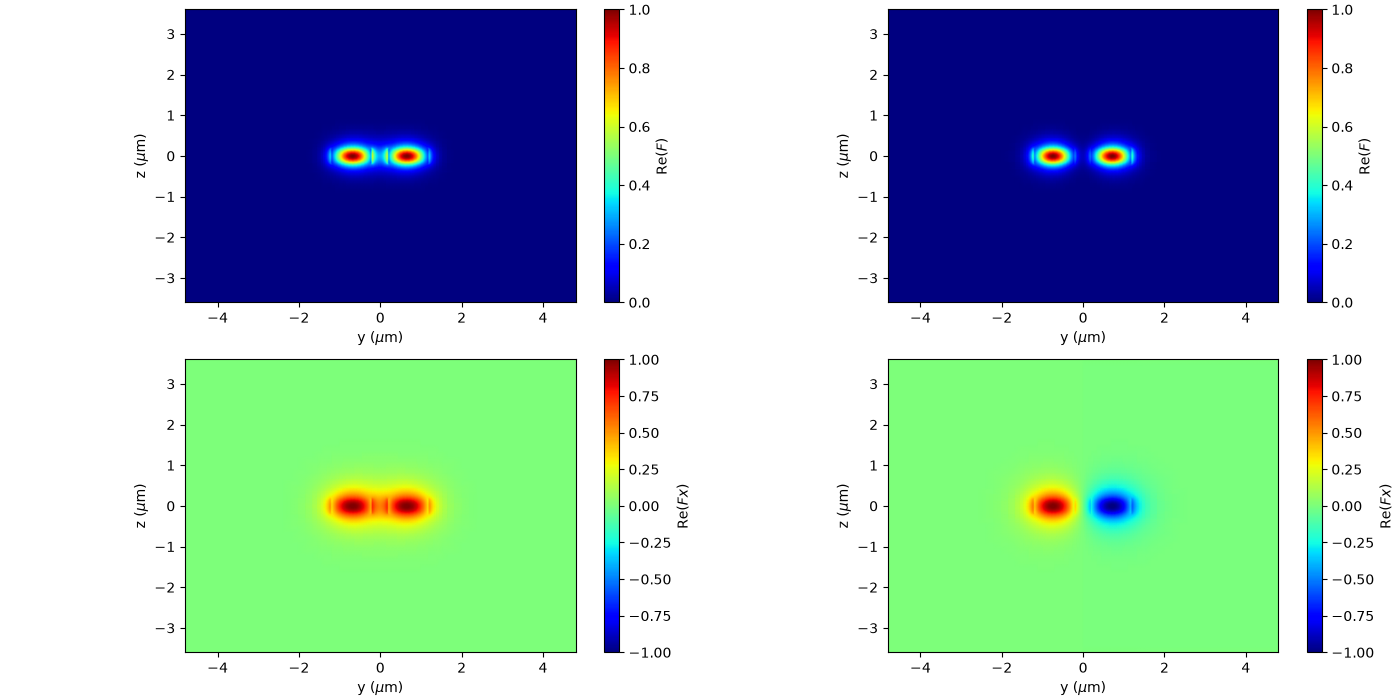

In [36]:
# Supermodes

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 7), constrained_layout=True)

E = solver.getresult("FDE::data::mode1", "E")
Ex, Ey, Ez = [np.squeeze(E["E"][..., i]) for i in range(3)]
y, z = np.squeeze(E["y"]), np.squeeze(E["z"])

px.plot_field(
    Ex, Ey, Ez, 
    y=y*1e6, z=z*1e6,
    ax=ax1,
    scale="lin"
)

px.plot_field(
    Ey, 
    y=y*1e6, z=z*1e6,
    ax=ax3,
    vmin=-1, vmax=1,
    scale="lin"
)

E = solver.getresult("FDE::data::mode2", "E")
Ex, Ey, Ez = [np.squeeze(E["E"][..., i]) for i in range(3)]
y, z = np.squeeze(E["y"]), np.squeeze(E["z"])

px.plot_field(
    Ex, Ey, Ez, 
    y=y*1e6, z=z*1e6,
    ax=ax2,
    scale="lin"
)

px.plot_field(
    Ey, 
    y=y*1e6, z=z*1e6,
    ax=ax4,
    vmin=-1, vmax=1,
    scale="lin"
)


plt.show()

## Gap Sweep

In [37]:
def update_gap_width(mode_solver, coupler_gap):
    core1_y = -(core_width + coupler_gap)/2
    core2_y = +(core_width + coupler_gap)/2

    mode_solver.switchtolayout()
    mode_solver.setnamed("coupler::core1", "y", core1_y)
    mode_solver.setnamed("coupler::core2", "y", core2_y)

def get_mode_data(mode_solver, mode_name):
    mode_data = {
        "f": mode_solver.getdata(mode_name, "f"),
        "neff": mode_solver.getdata(mode_name, "neff").item(),
        "ng": mode_solver.getdata(mode_name, "ng").item(),
        "loss": mode_solver.getdata(mode_name, "loss"),
        "TE polarization fraction": mode_solver.getdata(mode_name, "TE polarization fraction"),
        "waveguide TE-TM fraction": mode_solver.getdata(mode_name, "waveguide TE-TM fraction"),
        "mode effective area": mode_solver.getdata(mode_name, "mode effective area"),

        "x": mode_solver.getdata(mode_name, "x"),
        "y": mode_solver.getdata(mode_name, "y"),
        "z": mode_solver.getdata(mode_name, "z"),

        "Ex": mode_solver.getdata(mode_name, "Ex"),
        "Ey": mode_solver.getdata(mode_name, "Ex"),
        "Ez": mode_solver.getdata(mode_name, "Ex"),

        "Hx": mode_solver.getdata(mode_name, "Hx"),
        "Hy": mode_solver.getdata(mode_name, "Hy"),
        "Hz": mode_solver.getdata(mode_name, "Hz"),
    }
    
    return mode_data

In [38]:
sweep_data = []
for i, g in enumerate(reversed(gap_sweep)):
    # Update core width
    update_gap_width(solver, g)

    # Find modes
    solver.findmodes()
    mode1_data = get_mode_data(solver, "FDE::data::mode1")
    mode2_data = get_mode_data(solver, "FDE::data::mode2")

    sweep_data.append({
        "coupler_gap": g,
        "modes": [mode1_data, mode2_data ],
    })

# Cross-over length: $L_x = \frac{\lambda_0}{2 \cdot \Delta n_{\text{eff}}}$.

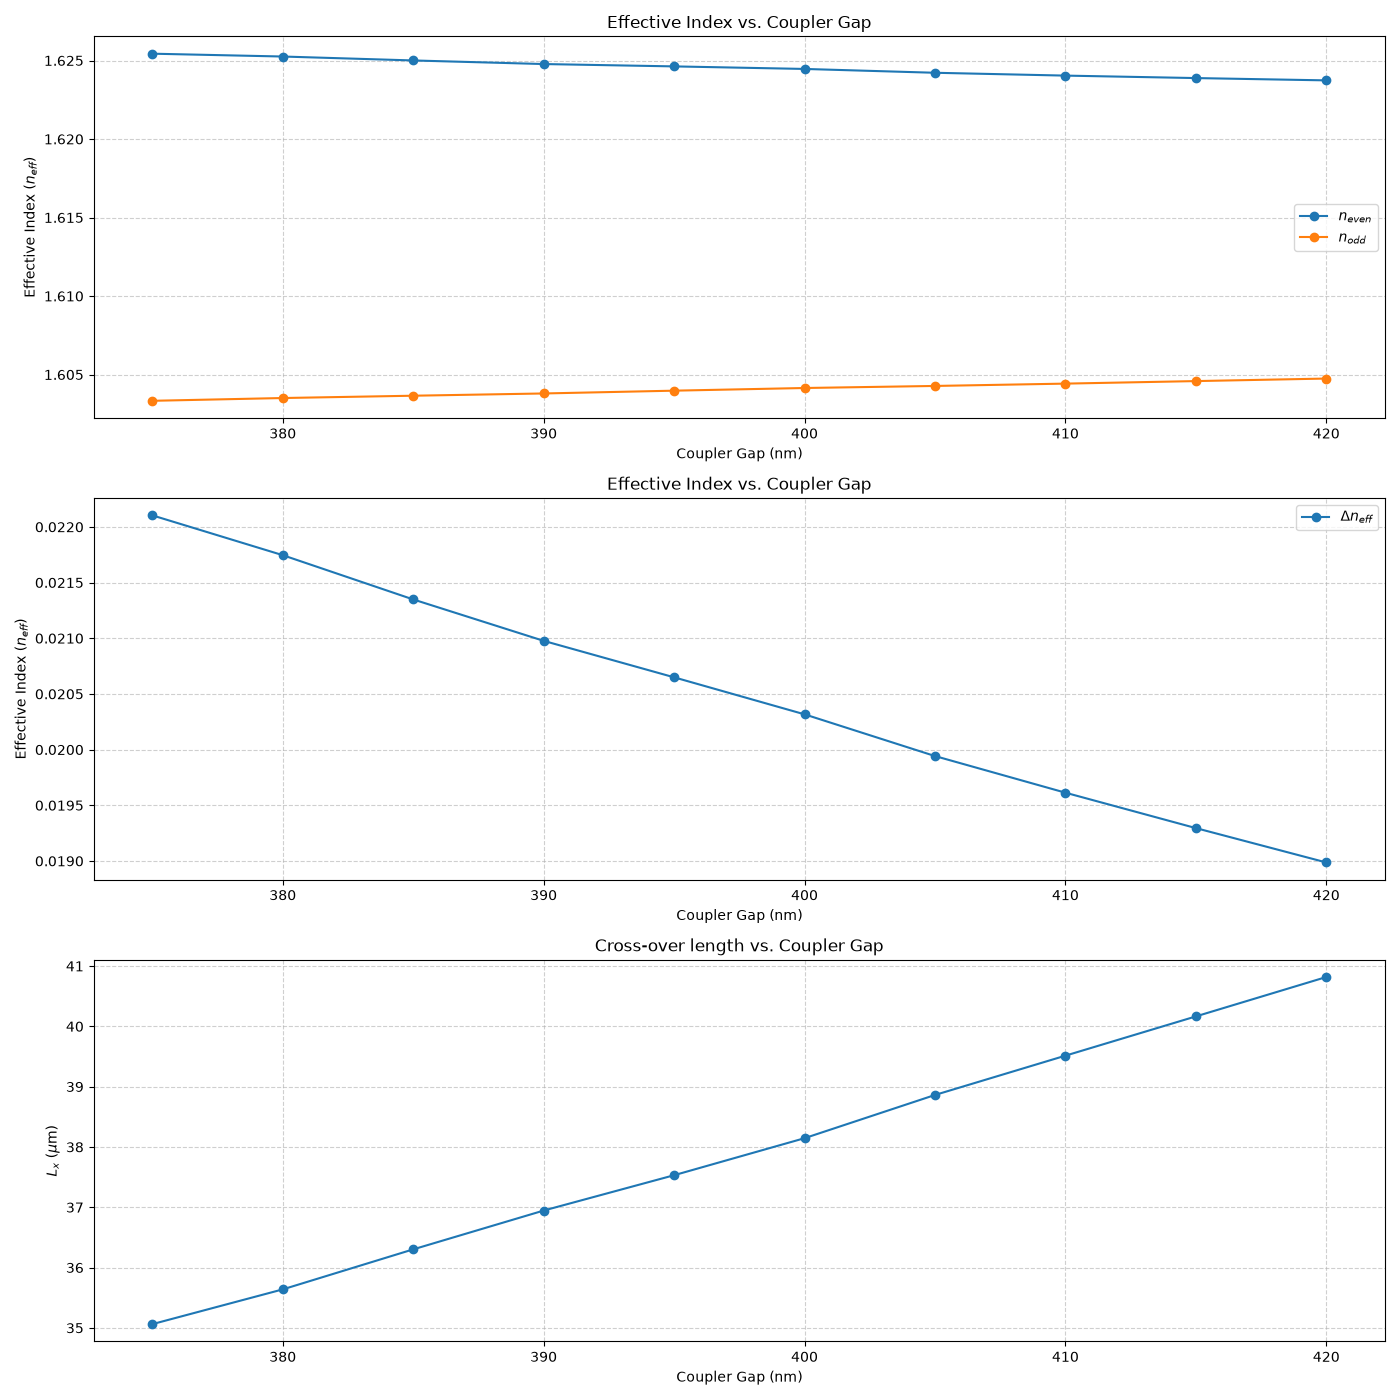

In [39]:
gaps_nm = np.array([step["coupler_gap"] * 1e9 for step in sweep_data])
neffs_matrix = np.full((len(sweep_data), 2), np.nan)

calc_delta = lambda n1, n2: n1 - n2
calc_lx = lambda wvl0, delta_n: (wvl0/(2*delta_n))
calc_k = lambda wvl0, delta_n, l: np.sin(((np.pi*delta_n)/wvl0)*l)
calc_t = lambda wvl0, delta_n, l: np.cos(((np.pi*delta_n)/wvl0)*l)

for i, step in enumerate(sweep_data):
    sorted_modes = sorted(step["modes"], key=lambda m: np.real(m["neff"]), reverse=True)
    for m_idx, mode in enumerate(sorted_modes[:2]):
        neffs_matrix[i, m_idx] = np.real(mode["neff"])

ns_even = neffs_matrix[:, 0]
ns_odd = neffs_matrix[:, 1]
deltas_n = calc_delta(ns_even, ns_odd)
lxs = calc_lx(wavelength_center, deltas_n)
lxs_um = lxs*1e6

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 14))

# Even modes
ax1.plot(
    gaps_nm,
    ns_even,
    marker="o",
    linestyle="-",
    label="$n_{even}$",
)

# Odd modes
ax1.plot(
    gaps_nm,
    ns_odd,
    marker="o",
    linestyle="-",
    label="$n_{odd}$",
)

ax1.set_title("Effective Index vs. Coupler Gap")
ax1.set_xlabel("Coupler Gap (nm)")
ax1.set_ylabel("Effective Index ($n_{eff}$)")
ax1.legend(fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.6)

# Delta n
ax2.plot(
    gaps_nm,
    deltas_n,
    marker="o",
    linestyle="-",
    label=r"$\Delta n_{eff}$",
)

ax2.set_title("Effective Index vs. Coupler Gap")
ax2.set_xlabel("Coupler Gap (nm)")
ax2.set_ylabel("Effective Index ($n_{eff}$)")
ax2.legend(fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.6)

ax3.plot(
    gaps_nm,
    lxs_um,
    marker="o",
    linestyle="-",
)

ax3.set_title("Cross-over length vs. Coupler Gap")
ax3.set_xlabel("Coupler Gap (nm)")
ax3.set_ylabel(r"$L_x$ ($\mu$m)"),
ax3.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

Gap: 400.0 nm


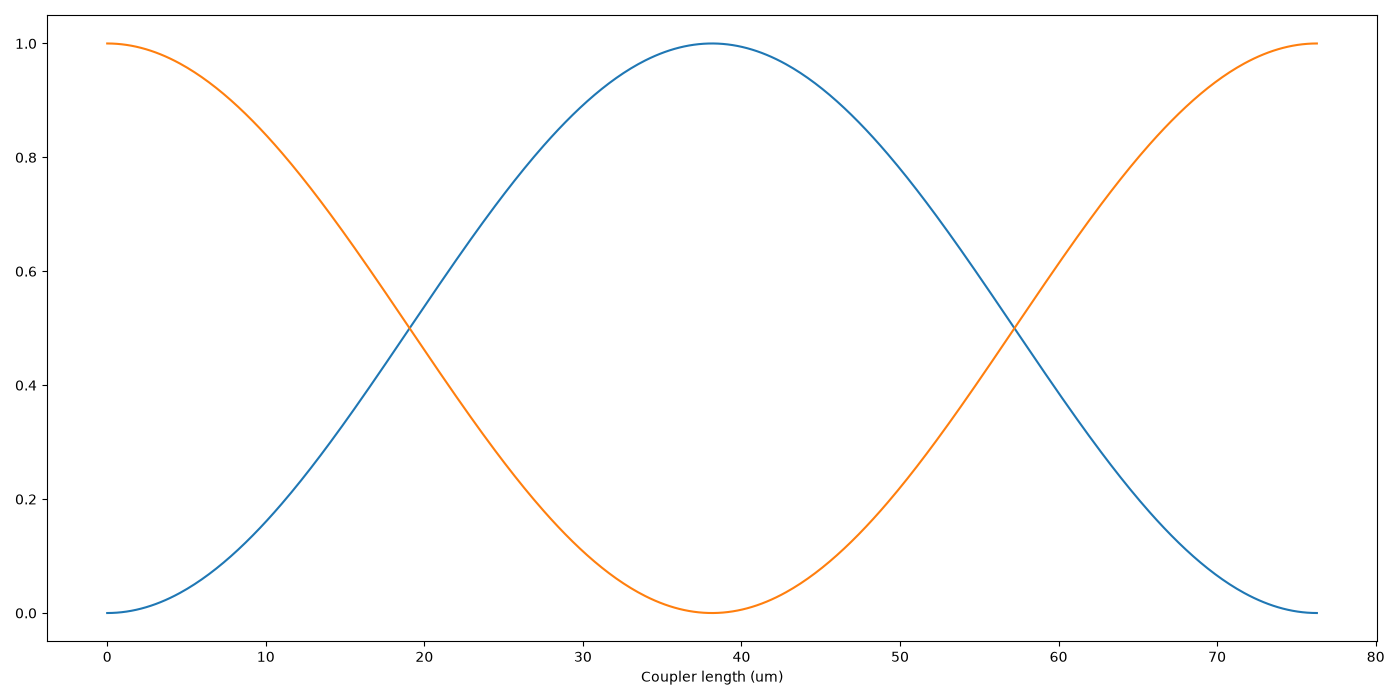

In [40]:
coupler_gap = [400.0]
g_idx = np.argmin(np.abs(gaps_nm - coupler_gap))
print(f"Gap: {gaps_nm[g_idx]:.1f} nm")
delta_n = deltas_n[g_idx]

lx = calc_lx(wavelength_center, delta_n)
ls = np.linspace(0, lx*2, 500)
ls_um = ls * 1e6

k2s = calc_k(wavelength_center, delta_n, ls)**2
t2s = calc_t(wavelength_center, delta_n, ls)**2

fig, ax1 = plt.subplots(1, 1, figsize=(14, 7))

ax1.plot(
    ls_um,
    k2s,
)

ax1.plot(
    ls_um,
    t2s,
)

ax1.set_xlabel("Coupler length (um)")
plt.tight_layout()
plt.show()

# FDTD simulation

In [41]:
# Get solver
solver = lma.FDTD(hide=False)

In [42]:
# Materials fitting

core_material = fit_material(base_core_material)
clad_material = fit_material(base_clad_material)
substrate_material = fit_material(base_substrate_material)

In [56]:
# Structures

coupler_gap = 400*nm
coupler_length = 19*um

solver.switchtolayout()

# Clad
remove(clad_rect["name"])
solver.addrect(clad_rect)

# Substrate
remove(substrate_rect["name"])
solver.addrect(substrate_rect)

# Coupler group
remove("coupler")
solver.addstructuregroup(name="coupler")

# Core 1
remove(core1_rect["name"])
core1_rect["x span"] = coupler_length
solver.addrect(core1_rect)
solver.addtogroup("coupler")

port1 = (
    -(coupler_length/2),
    +(coupler_gap/2 + core_width/2)
)
port2 = (
    -(coupler_length/2),
    -(coupler_gap/2 + core_width/2)
)

# Core 2
remove(core2_rect["name"])
core2_rect["x span"] = coupler_length
solver.addrect(core2_rect)
solver.addtogroup("coupler")

port3 = (
    +(coupler_length/2),
    +(coupler_gap/2 + core_width/2)
)
port4 = (
    +(coupler_length/2),
    -(coupler_gap/2 + core_width/2)
)

In [57]:
# Simulation setup

initial_fdtd_length = coupler_length + fde_buffer
initial_fdtd_width = initial_fde_width
initial_fdtd_height = initial_fde_height

solver.switchtolayout()

# FDTD
remove("FDTD")
solver.addfdtd(
    x=0, x_span=initial_fdtd_length, 
    y=0, y_span=initial_fdtd_width,
    z=0, z_span=initial_fdtd_height
)

solver.setdevice("GPU")
solver.setglobalsource("wavelength start", wavelength_center - wavelength_span/2)
solver.setglobalsource("wavelength stop", wavelength_center + wavelength_span/2)

# Port1
remove("port1")
solver.addport(
    name="port1",
    injection_axis="x-axis",
    x=port1[0] - ports_offset,
    y=port1[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

# Port2
remove("port2")
solver.addport(
    name="port2",
    injection_axis="x-axis",
    x=port2[0] - ports_offset,
    y=port2[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

# Port3
remove("port3")
solver.addport(
    name="port3",
    injection_axis="x-axis",
    x=port3[0] + ports_offset,
    y=port3[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Backward",
    mode_selection="fundamental TE mode",
);

# Port4
remove("port4")
solver.addport(
    name="port4",
    injection_axis="x-axis",
    x=port4[0] + ports_offset,
    y=port4[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Backward",
    mode_selection="fundamental TE mode",
);

solver.setnamed("FDTD::ports", "override global monitor settings", False)

# Index monitor
remove("index-monitor")
solver.addindex(
    name="index-monitor",
    monitor_type="2D Z-normal",
    x=0, x_span=initial_fdtd_length, 
    y=0, y_span=initial_fdtd_width,
    z=0,
)

# Field monitor
remove("field-monitor")
solver.adddftmonitor(
    name="field-monitor",
    monitor_type="2D Z-normal",
    x=0, x_span=initial_fdtd_length,
    y=0, y_span=initial_fdtd_width,
    z=0,
)

solver.setglobalmonitor("frequency points", 30)

# Global mesh
solver.setnamed("FDTD", "mesh accuracy", 3)

solver.save(f"/tmp/{experiment_name}.fsp")

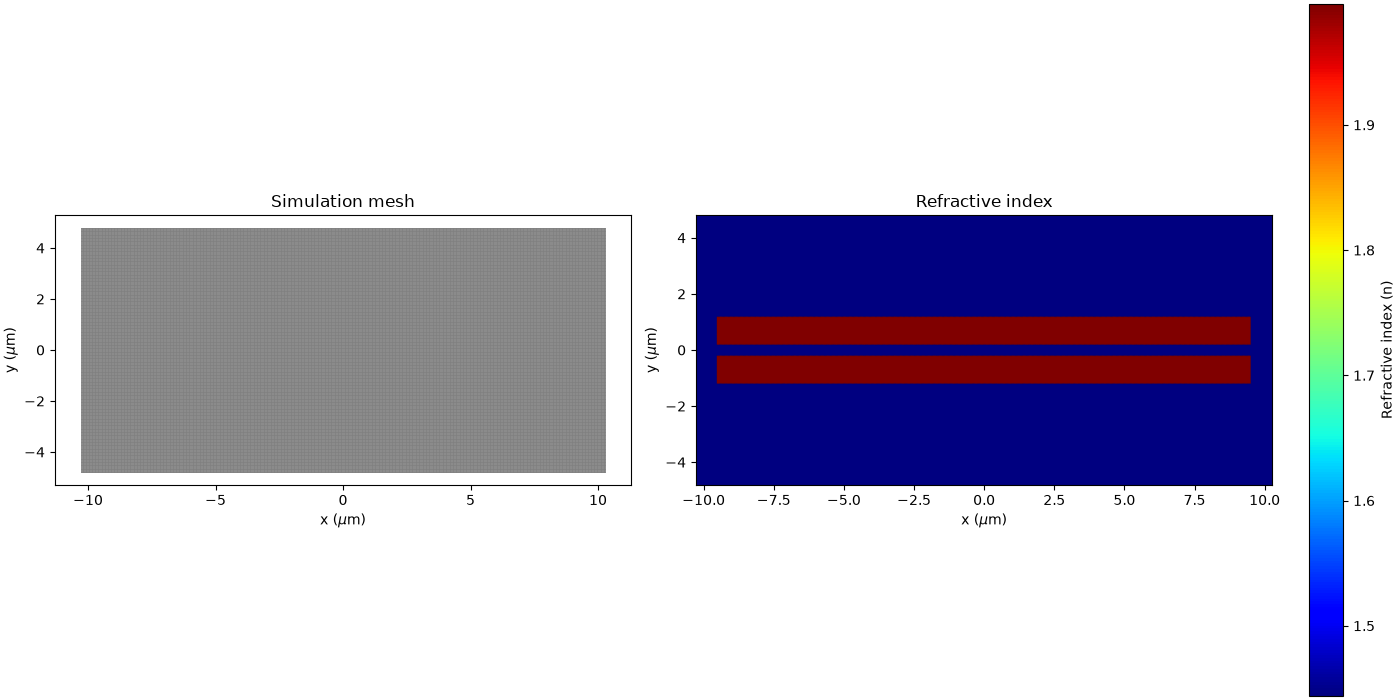

In [58]:
# Simulation preview

index = solver.getresult("index-monitor", "index preview")
index_x, index_y, index_z = [np.squeeze(index[f"index_{a}"]) for a in ["x", "y", "z"]]
x, y = np.squeeze(index["x"]), np.squeeze(index["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Grid
X, Y = np.meshgrid(x, y, indexing='ij')
ax1.plot(X * 1e6, Y * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.plot(X.T * 1e6, Y.T * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.set_title('Simulation mesh')
ax1.set_xlabel(r'x ($\mu$m)')
ax1.set_ylabel(r'y ($\mu$m)')
ax1.set_aspect('equal')

# Refractive index
im2 = px.plot_field(
    Fx=index_x,
    x=x*1e6, y=y*1e6,
    ax=ax2,
    scale="lin",
)
ax2.set_title('Refractive index')
im2.colorbar.set_label('Refractive index (n)')

solver.setnamed("index-monitor", "enabled", False)

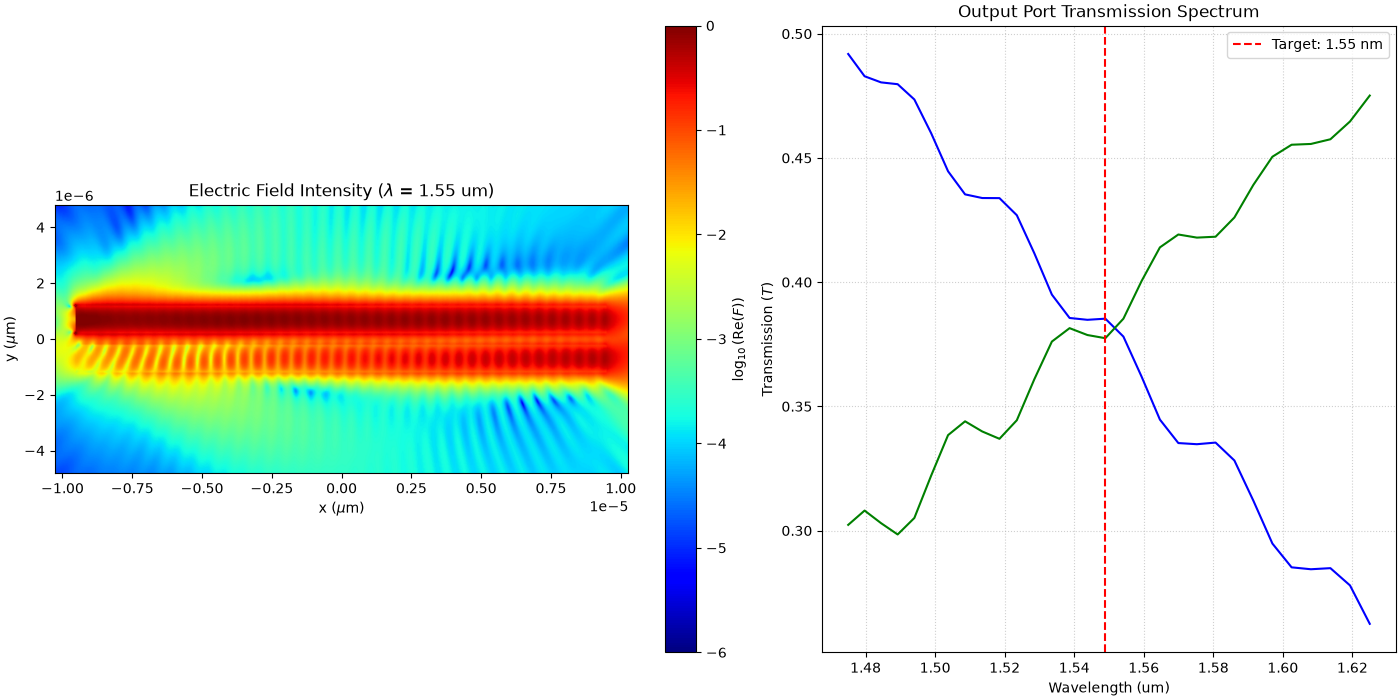

In [59]:
# Initial simulation

solver.run()

# Get E fields components from field-monitor
E = solver.getresult("field-monitor", "E")

# Get index of wavelength nearest center
lambdas = np.squeeze(E["lambda"])
lambda_idx = np.argmin(np.abs(lambdas - wavelength_center))
plot_wavelength = lambdas[lambda_idx]

Ex, Ey, Ez = [np.squeeze(E["E"][..., lambda_idx,i ]) for i in range(3)]
x, y = np.squeeze(E["x"]), np.squeeze(E["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, y=y,
    vmin=-6, vmax=0,
    ax=ax1
)
ax1.set_title(rf'Electric Field Intensity ($\lambda$ = {plot_wavelength*1e6:.2f} um)')

# Transmission
T3 = solver.getresult("FDTD::ports::port3", "T")
wavelengths = np.squeeze(T3["lambda"])
T3 = np.squeeze(T3["T"])

T4 = solver.getresult("FDTD::ports::port4", "T")
T4 = np.squeeze(T4["T"])


ax2.plot(wavelengths*1e6, T3, color='b')
ax2.plot(wavelengths*1e6, T4, color='g')
ax2.axvline(plot_wavelength*1e6, color='r', linestyle='--', label=f'Target: {plot_wavelength*1e6:.2f} nm')
ax2.set_xlabel('Wavelength (um)')
ax2.set_ylabel('Transmission ($T$)')
ax2.set_title('Output Port Transmission Spectrum')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.show()